# 434 Lab 3 Report

**Name:** Austin Birkhofer

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from IPython.display import display

rng = np.random.default_rng(4343)
plt.rcParams["figure.figsize"] = (9, 5)

## Problem 1

### Part A.0

The good data follows a model of $T\sim\mathcal N(12,0.4^2)$ K. I generated 100,000 good observations and add the eight bad readings.

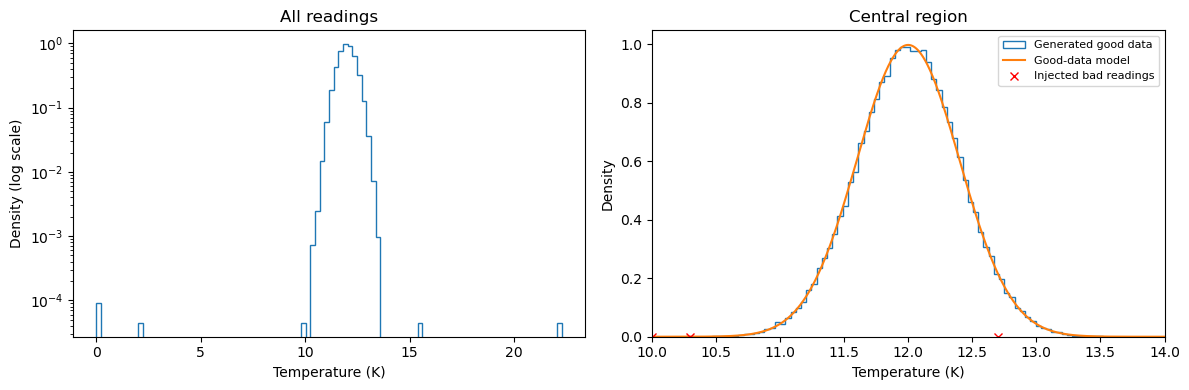

In [2]:
mu = 12.0
sigma = 0.4
n_good = 100000
good = stats.norm.rvs(loc=mu, scale=sigma, size=n_good, random_state=rng)
bad = np.array([10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
d = np.append(good, bad)
true_good = np.append(np.ones(n_good, dtype=bool), np.zeros(len(bad), dtype=bool))
assert len(d) == len(true_good) == 100008

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(d, bins=100, density=True, histtype="step")
axes[0].set_yscale("log")
axes[0].set(xlabel="Temperature (K)", ylabel="Density (log scale)", title="All readings")
x = np.linspace(10, 14, 1000)
axes[1].hist(good, bins=80, density=True, histtype="step", label="Generated good data")
axes[1].plot(x, stats.norm.pdf(x, loc=mu, scale=sigma), label="Good-data model")
axes[1].plot(bad, np.zeros(len(bad)), "rx", label="Injected bad readings")
axes[1].set(xlim=(10, 14), xlabel="Temperature (K)", ylabel="Density", title="Central region")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

### Part A.1

**Quetion:** If a reading came from the good data model, how often would its absolute deviation from 12 K be at least as large as observed? Test is two sided since both high and low readings affect data quality.

### Part A.2

For an observation $t$,

$$z(t)=\frac{t-12}{0.4},\qquad
p_2(t)=P(|T-12|\geq|t-12|)=2\Phi(-|z(t)|).$$

I choose a four std dev screening threshold, so reject if $|z|>4$, or $t<10.4$ K or $t>13.6$ K. The two sided false rejection prob is $\alpha=2\Phi(-4)\approx6.33\times10^{-5}$.

### Part A.3

In [4]:
z = (d - mu) / sigma
p_two_sided = 2 * stats.norm.sf(np.abs(z))
z_cut = 4.0
reject = np.abs(z) > z_cut
alpha = 2 * stats.norm.sf(z_cut)
assert np.array_equal(reject, p_two_sided < alpha)

truth_table = pd.DataFrame([
    [np.sum(~reject & true_good), np.sum(~reject & ~true_good)],
    [np.sum(reject & true_good), np.sum(reject & ~true_good)]
], index=["Test Good (keep)", "Test Bad (discard)"],
   columns=["True Good", "Injected Bad"])
display(truth_table)
print(f"Keep interval: [{mu-z_cut*sigma:.1f}, {mu+z_cut*sigma:.1f}] K")
print(f"Two sided false rejection probability: {alpha:.8g}")

audit = pd.DataFrame({"Injected reading (K)": bad,
                      "abs(z)": np.abs((bad-mu)/sigma),
                      "Two-sided p": p_two_sided[n_good:],
                      "Discard": reject[n_good:]})
display(audit)
assert truth_table.to_numpy().sum() == len(d)
assert reject[n_good:].sum() == 7

,True Good,Injected Bad
Test Good (keep),99994,1
Test Bad (discard),6,7


Keep interval: [10.4, 13.6] K
Two sided false rejection probability: 6.3342484e-05


,Injected reading (K),abs(z),Two-sided p,Discard
0,10.0,5.00,5.733031e-07,True
1,10.3,4.25,2.137705e-05,True
2,2.1,24.75,3.100287e-135,True
3,0.0,30.00,9.813428e-198,True
4,0.0,30.00,9.813428e-198,True
5,15.6,9.00,2.257177e-19,True
6,22.3,25.75,3.223427e-146,True
7,12.7,1.75,8.011831e-02,False


### Part B

For a cutoff $c$, a actual good point is rejected with prob $\alpha(c)=2\Phi(-c)$. So the number $F$ of falsely rejected good points has

$$F\sim\operatorname{Binomial}(100000,\alpha),\qquad
E[F]=100000\alpha,\quad
\sigma_F=\sqrt{100000\alpha(1-\alpha)}.$$

At $c=4$, we expect about 6.33 false rejections. Raising the cutoff reduces good data losses while lowering it increases them. A three sigma cut would discard about 270 genuine good readings in a sample this large.

### Part C

A four sigma cut accepts the injected 12.7 K reading because it is only 1.75 standard deviations high. Catching it requires a cutoff below 1.75, which would reject more than about 8% of good Gaussian readings. A temp only threshold cannot perfectly separate labels whose observed values overlap. So we have to find a balance!

## Problem 2

### Part 1

**Question:** If a candidate is a stationary star, what is the prob of a displacement at least as large as the observed distance in any direction?

### Part 2

The horizontal and vertical displacements are modeled as independent normal random variables

$$
X,Y \sim \mathcal{N}(0,\sigma^2).
$$

So, $\sigma=1$ arcsecond in each coordinate. The total displacement is

$$
R=\sqrt{X^2+Y^2}.
$$

Although the components are normally distributed, their combined distance is not. Distance is nonnegative and includes displacement in every direction.

The joint probability density of the two components is

$$
f_{X,Y}(x,y)=\frac{1}{2\pi\sigma^2}
\exp\left(-\frac{x^2+y^2}{2\sigma^2}\right).
$$

The Rayleigh wiki page shows that the distance follows a Rayleigh distribution

$$
f_R(r)=\frac{r}{\sigma^2}
\exp\left(-\frac{r^2}{2\sigma^2}\right),
\qquad r\ge0.
$$

For an observed displacement $r_{\mathrm{obs}}$, we integrate over all larger distances:

$$
p=P(R\ge r_{\mathrm{obs}})
=\int_{r_{\mathrm{obs}}}^{\infty}
\frac{r}{\sigma^2}
\exp\left(-\frac{r^2}{2\sigma^2}\right)\,dr.
$$

Because

$$
\frac{d}{dr}\left[-\exp\left(-\frac{r^2}{2\sigma^2}\right)\right]
=
\frac{r}{\sigma^2}
\exp\left(-\frac{r^2}{2\sigma^2}\right),
$$

the integral evaluates to

$$
p=\exp\left(-\frac{r_{\mathrm{obs}}^2}{2\sigma^2}\right).
$$

This is the probability that a stationary object appears to move at least as far as the observed distance because of noise alone. A smaller probability means the observed displacement is harder to explain using the stationary-object model.

### Part 3

For one-sided Gaussian-equivalent five sigma, $\alpha=\Phi(-5)$. So from above, we have $$\boxed{r_5=\sigma\sqrt{-2\ln\alpha}=5.4891\ \text{arcseconds}.}$$

One sided five sigma tail: 2.8665157e-07
Motion threshold (1 arcsec per coordinate SD): 5.4891 arcsec
Expected false motion detections among 100000: 0.0287


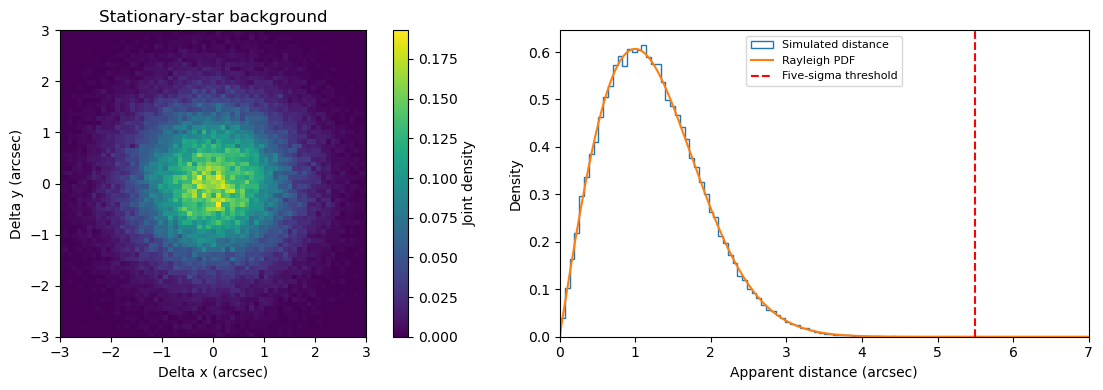

In [9]:
sigma_position = 1.0
n_stars = 100000
a = np.vstack((stats.norm.rvs(scale=sigma_position, size=n_stars, random_state=rng),
               stats.norm.rvs(scale=sigma_position, size=n_stars, random_state=rng)))
radius = np.hypot(a[0], a[1])
alpha5 = stats.norm.sf(5)
r5 = stats.rayleigh.isf(alpha5, scale=sigma_position)
assert np.isclose(r5, sigma_position*np.sqrt(-2*np.log(alpha5)))
assert np.isclose(stats.rayleigh.sf(r5, scale=sigma_position), alpha5)
print(f"One sided five sigma tail: {alpha5:.8g}")
print(f"Motion threshold (1 arcsec per coordinate SD): {r5:.4f} arcsec")
print(f"Expected false motion detections among {n_stars}: {n_stars*alpha5:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
h = axes[0].hist2d(a[0], a[1], bins=100, density=True)
axes[0].set_aspect("equal", "box")
axes[0].set(xlim=(-3, 3), ylim=(-3, 3), xlabel="Delta x (arcsec)",
            ylabel="Delta y (arcsec)", title="Stationary-star background")
fig.colorbar(h[3], ax=axes[0], label="Joint density")
r = np.linspace(0, 7, 1000)
axes[1].hist(radius, bins=80, density=True, histtype="step", label="Simulated distance")
axes[1].plot(r, stats.rayleigh.pdf(r, scale=sigma_position), label="Rayleigh PDF")
axes[1].axvline(r5, color="red", linestyle="--", label="Five-sigma threshold")
axes[1].set(xlim=(0, 7), xlabel="Apparent distance (arcsec)", ylabel="Density")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Problem 3

### Part 1

**Question:** If the Moon caused no shadow and the mean cosmic ray rate stayed at one per minute, what is the prob of observing 6800 or fewer counts in this patch and observing period?

### Part 2

We use a Poisson distrubition because of the set arrival rate and independent arrival events. The exposure is $8\times60\times15=7200$ minutes and it is 1 event per minute, so under no shadow

$$K\sim\operatorname{Poisson}(7200),\qquad
P(K=k)=e^{-7200}\frac{7200^k}{k!}.$$

We observed 6800 events, a deficit of

$$
7200-6800=400.
$$

Because the Moon would produce a shortage, the relevant probability includes all counts at or below the observation. We therefore calculate a lower-tail probability:

$$
p=P(N\le6800\mid\lambda=7200).
$$

Counts are discrete, so we sum probabilities rather than integrate a continuous density:

$$
p=\sum_{k=0}^{6800}
\frac{e^{-7200}7200^k}{k!}.
$$

This gets us

$$
\boxed{p\approx1.0133\times10^{-6}.}
$$

### Part 3

To get the result in sigma units, we find the standard normal upper tail probability equal to the Poisson deficit probability. Let $Z\sim\mathcal{N}(0,1)$. We need $z$ satisfying

$$
P(Z\ge z)=p.
$$

If $\Phi$ is the standard normal cdf, then

$$
1-\Phi(z)=p,
$$

so

$$
z=\Phi^{-1}(1-p).
$$

Using the Poisson prob,

$$
z=\Phi^{-1}\left(1-1.0133\times10^{-6}\right)
\approx4.7507.
$$

Therefore, the Moon shadow deficit has a one sided equivalent signif of

$$
\boxed{z\approx4.75\,\sigma.}
$$